# Lab 5 Task 1: Deterministic OFDM Transmitter

Complete the OFDM accounting, build the deterministic frame, verify the QPSK and cyclic-prefix round trips, and inspect the supplied frame and resource-grid plots.


In [1]:
from pathlib import Path
import json
import os
import sys
import numpy as np
from IPython.display import Image, display
import IPython.core.pylabtools as pylabtools

# Matplotlib 3.6 expects this compatibility table, which newer IPython omits.
if not hasattr(pylabtools, "backend2gui"):
    pylabtools.backend2gui = {}

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab5_dsp.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 5 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB5_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

import lab5_dsp as lab
import lab5_tools

print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/captures


## OFDM timing and carrier calculations


<span style="color:#165696"><b>Report.</b> Show the timing, carrier, and bit-count calculations. </span>

**Timing Calculations**

Subcarrier spacing $\Delta f=\frac{f_s}{N_{FFT}}=\frac{1{,}000{,}000}{64}=15{,}625\ \text{Hz}$

Useful OFDM symbol duration $T_u=\frac{N_{FFT}}{f_s}=\frac{64}{1{,}000{,}000}=64\ \mu s$

Cyclic prefix (CP) duration $T_{CP}=\frac{N_{CP}}{f_s}=\frac{16}{1{,}000{,}000}=16\ \mu s$

Total OFDM symbol duration $T_{sym}=\frac{N_{FFT}+N_{CP}}{f_s}=\frac{64+16}{1{,}000{,}000}=\frac{80}{1{,}000{,}000}=80\ \mu s$

**Carrier Calculations**

Number of data carriers $N_{data}=N_{active}-N_{pilot}=52-4=48$

Signed-carrier to array-index mapping $i=k \bmod 64$

$-26\rightarrow38,\ -21\rightarrow43,\ -1\rightarrow63,\ 1\rightarrow1,\ 21\rightarrow21,\ 26\rightarrow26$

**Bit-Count Calculations**

Bits per OFDM payload symbol (QPSK) $\text{Bits/symbol}=48\times2=96\ \text{bits}$

Bits per frame $\text{Bits/frame}=20\times96=1920\ \text{bits}$

In [6]:
sample_rate_sps = 1_000_000
nfft = 64
ncp = 16
active_carriers = 52
pilot_carriers = 4
payload_symbols = 20

# Derived quantities
subcarrier_spacing_hz = sample_rate_sps / nfft
useful_symbol_seconds = nfft / sample_rate_sps
cp_seconds = ncp / sample_rate_sps
total_symbol_seconds = (nfft + ncp) / sample_rate_sps

data_carriers = active_carriers - pilot_carriers
bits_per_payload_symbol = data_carriers * 2   # QPSK = 2 bits/carrier
bits_per_frame = payload_symbols * bits_per_payload_symbol

signed_examples = (-26, -21, -1, 1, 21, 26)
array_indices = {k: k % nfft for k in signed_exampçles}

print("subcarrier spacing (Hz):", subcarrier_spacing_hz)
print("useful, CP, total durations (us):",
      1e6*useful_symbol_seconds,
      1e6*cp_seconds,
      1e6*total_symbol_seconds)
print("data carriers, bits/symbol, bits/frame:",
      data_carriers,
      bits_per_payload_symbol,
      bits_per_frame)
print("signed carrier to array index:", array_indices)

subcarrier spacing (Hz): 15625.0
useful, CP, total durations (us): 64.0 16.0 80.0
data carriers, bits/symbol, bits/frame: 48 96 1920
signed carrier to array index: {-26: 38, -21: 43, -1: 63, 1: 1, 21: 21, 26: 26}


In [7]:
assert subcarrier_spacing_hz == 15_625
assert np.isclose(useful_symbol_seconds, 64e-6)
assert np.isclose(cp_seconds, 16e-6)
assert np.isclose(total_symbol_seconds, 80e-6)
assert data_carriers == 48
assert bits_per_payload_symbol == 96
assert bits_per_frame == 1920
assert array_indices == {-26: 38, -21: 43, -1: 63, 1: 1, 21: 21, 26: 26}
print("Task 1 calculations passed.")


Task 1 calculations passed.


## Construct and verify the frame


<span style="color:#165696"><b>Report.</b> Report scale, PAPR, ideal BER, EVM, grid error, and null-carrier error. </span>

In [9]:
reference = lab.build_reference_frame(sequence_number=0)
ideal = lab.ideal_round_trip(reference)
payload_cp = lab.ofdm_modulate(reference.payload_grid, reference.ncp)
recovered_grid = lab.ofdm_demodulate(payload_cp, reference.ncp)

print("active frame samples:", reference.active_frame_length)
print("logical period samples:", reference.logical_period.size)
print("TX scale:", reference.tx_scale)
print("PAPR (dB):", reference.papr_db)
print("ideal results:", ideal)
print("maximum CP-copy error:", np.max(np.abs(payload_cp[:, :ncp] - payload_cp[:, -ncp:])))


active frame samples: 2080
logical period samples: 8192
TX scale: 0.043817606374807375
PAPR (dB): 8.134155266966252
ideal results: {'ber': 0.0, 'bit_errors': 0, 'evm_rms': 1.597252441496604e-16, 'max_grid_error': 5.026748538604307e-16, 'max_null': 5.026748538604307e-16}
maximum CP-copy error: 0.0


In [10]:
assert reference.active_frame_length == 2080
assert reference.logical_period.size == 8192
assert np.max(np.abs(reference.tx_period)) <= 0.1000001
assert np.allclose(recovered_grid, reference.payload_grid, atol=4e-7)
assert ideal["bit_errors"] == 0
print("Deterministic frame checks passed.")


Deterministic frame checks passed.


## Supplied plots


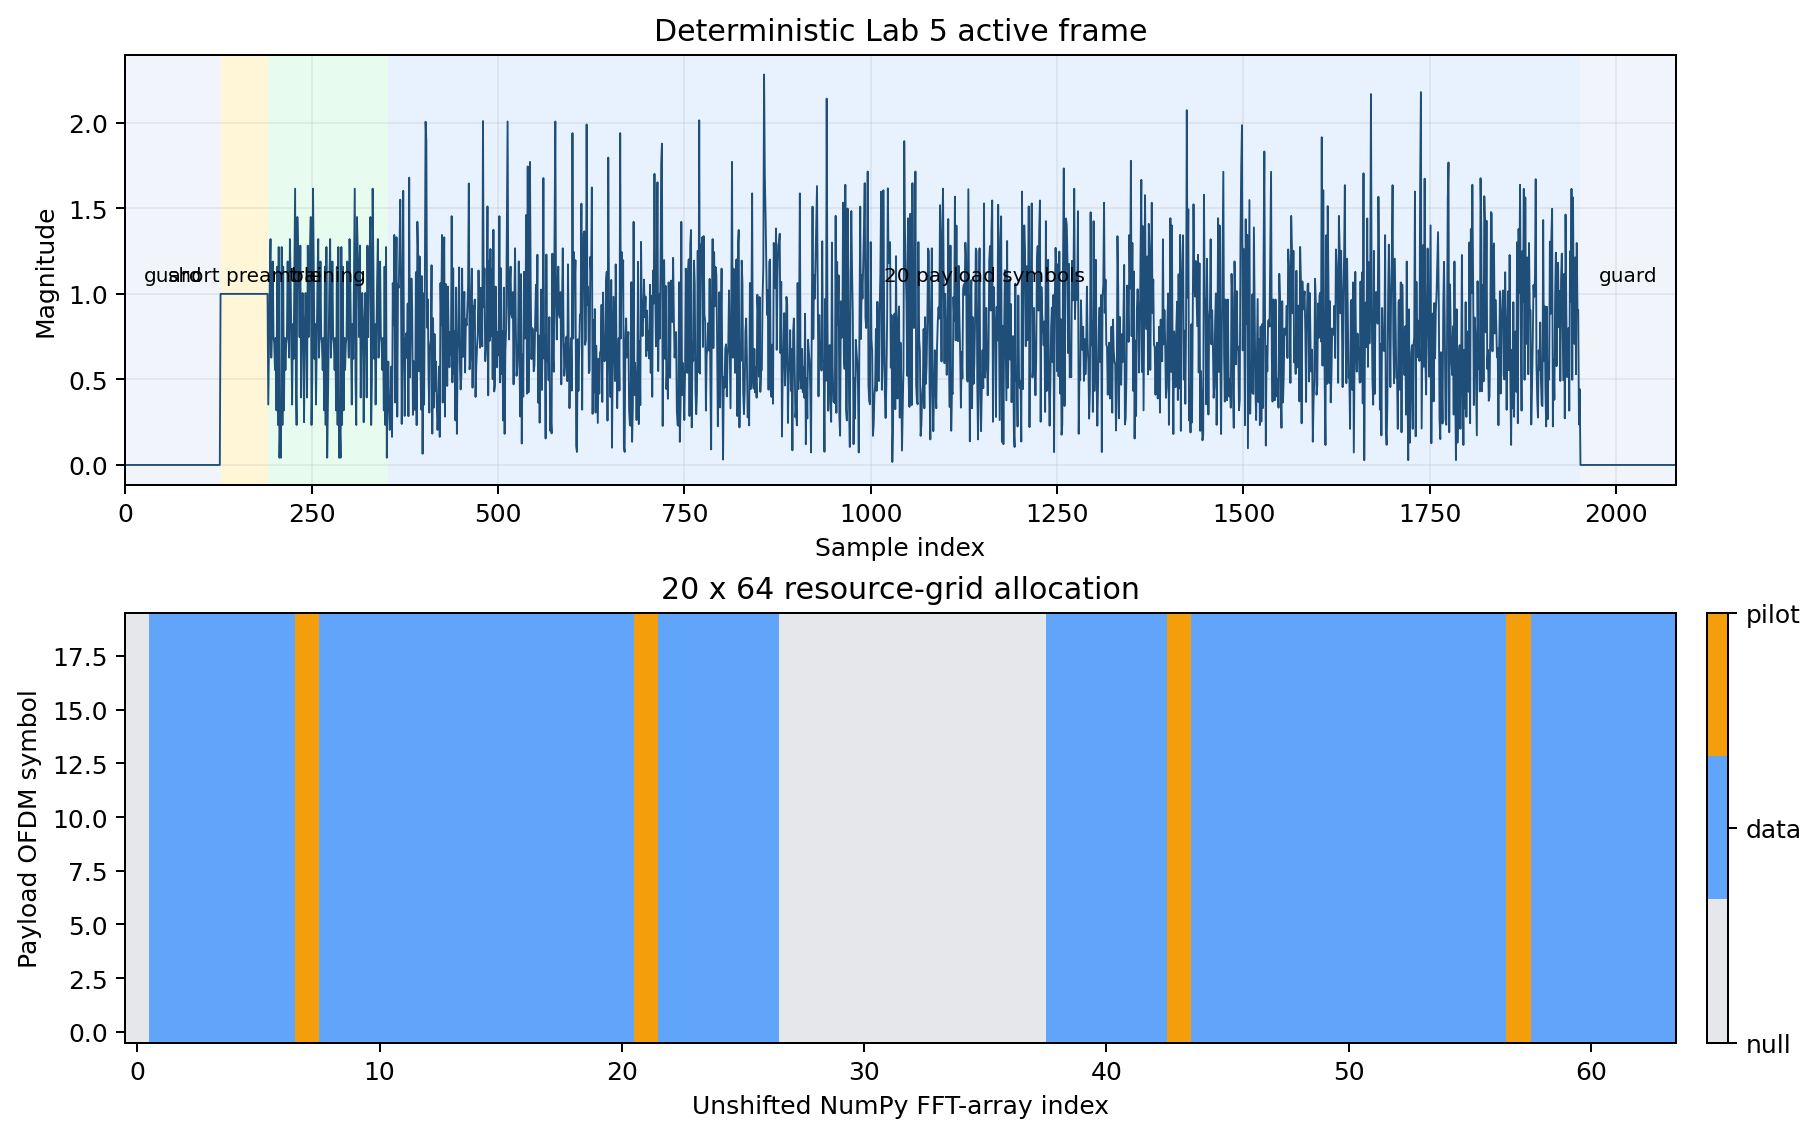

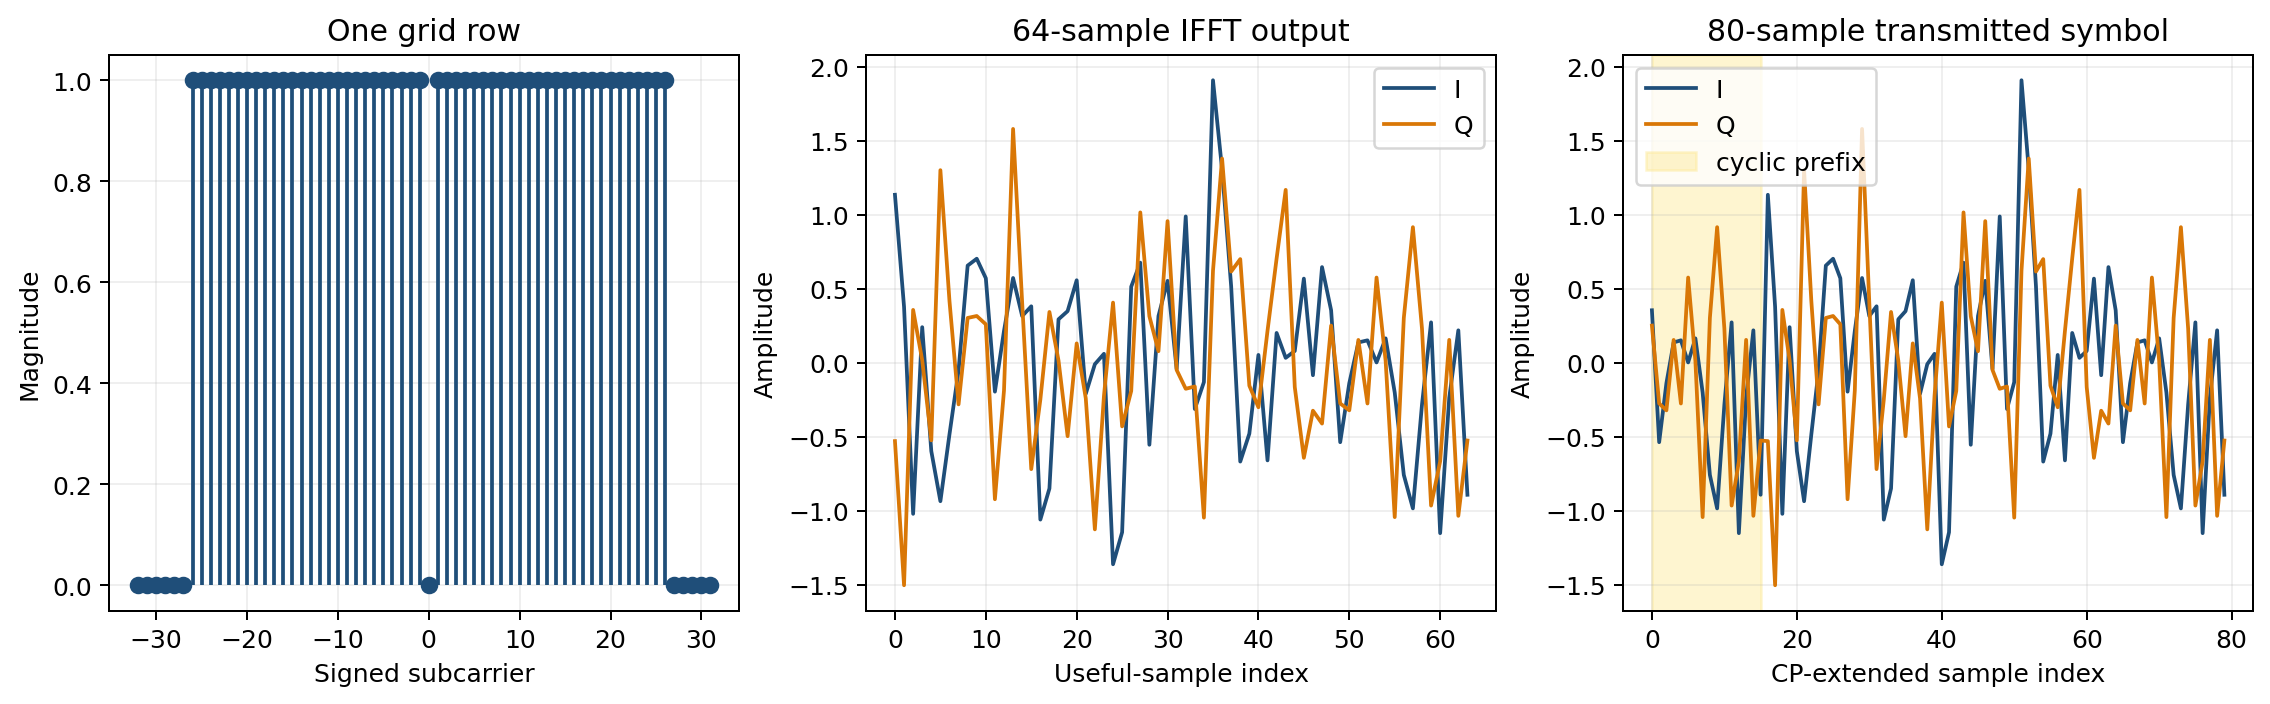

In [11]:
simulation = lab5_tools.generate_simulation(FIGURE_DIR)
for name in ('task1_frame_and_resource_grid', 'task1_ofdm_symbol'):
    path = FIGURE_DIR / f"{name}.png"
    display(Image(filename=path))


## Report work

<span style="color:#165696"><b>Report.</b> Explain why signed negative subcarriers map to the upper NumPy indices. </span>

In the N-point DFT, frequency bins are represented modulo N, so negative frequencies wrap around to the end of the array. As a result, a signed carrier index k is mapped using $i=k \bmod N_{FFT}$, causing carriers such as −1 and −21 to appear at indices 63 and 43 when $N_{FFT}=64$. This arrangement allows NumPy FFT functions to represent both positive and negative frequency components in a single unshifted array. Using this mapping ensures the transmitter and receiver place symbols on the correct subcarriers and maintain OFDM orthogonality.

<span style="color:#165696"><b>Report.</b> Explain why the CP contains the final samples of the useful symbol. </span>

The cyclic prefix is created by copying the last $N_{CP}$ samples of the useful OFDM symbol and placing them at the beginning of the symbol. This makes the transmitted waveform appear periodic over the FFT window, allowing the receiver to model the channel's linear convolution as a circular convolution. When the channel delay spread is shorter than the CP length, intersymbol interference is confined to the CP and does not affect the useful data samples. As a result, each subcarrier experiences only a complex gain H[k], enabling simple one-tap frequency-domain equalization.

<span style="color:#165696"><b>Report.</b> Explain why clipping would destroy orthogonality even if the FFT implementation is correct. </span>

Clipping is a nonlinear operation that distorts the transmitted OFDM waveform whenever signal peaks exceed the allowed amplitude range. This distortion generates additional frequency components that were not present in the original set of orthogonal subcarriers, causing energy from one subcarrier to leak into others. The resulting intercarrier interference breaks the assumption that each subcarrier can be separated perfectly by the FFT, even if the FFT itself is implemented correctly. Therefore, clipping degrades constellation quality, increases EVM and BER, and reduces overall OFDM performance.|